In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv("../data/processed/sales_analysis_ready.csv",
                 parse_dates=["order_date", "ship_date"],
                 dtype={"postal_code": str})
print(df.shape)
print(round(df["sales"].sum(), 2), round(df["profit"].sum(), 2))

(9993, 27)
2296919.49 286409.08


In [2]:
snapshot_date = df["order_date"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date.date())

customers = (df.groupby(["customer_id", "customer_name", "segment"])
               .agg(first_order=("order_date", "min"),
                    last_order=("order_date", "max"),
                    orders=("order_id", "nunique"),
                    total_sales=("sales", "sum"),
                    total_profit=("profit", "sum"))
               .reset_index())

customers["recency_days"] = (snapshot_date - customers["last_order"]).dt.days
customers["avg_order_value"] = customers["total_sales"] / customers["orders"]
customers["profit_margin_pct"] = customers["total_profit"] / customers["total_sales"] * 100

print("Customers:", len(customers))
print("Sum of orders:", customers["orders"].sum())
print("Sum of sales:", round(customers["total_sales"].sum(), 2))
print("Earliest first order:", customers["first_order"].min().date())
print("Latest last order:", customers["last_order"].max().date())

customers[["recency_days", "orders", "total_sales"]].describe(
    percentiles=[0.2, 0.4, 0.6, 0.8]).T

Snapshot date: 2017-12-31
Customers: 793
Sum of orders: 5009
Sum of sales: 2296919.49
Earliest first order: 2014-01-03
Latest last order: 2017-12-30


,count,mean,std,min,20%,40%,60%,80%,max
recency_days,793.00,147.80,186.21,1.00,27.00,54.00,104.00,225.60,"1,166.00"
orders,793.00,6.32,2.55,1.00,4.00,5.00,7.00,8.60,17.00
total_sales,793.00,"2,896.49","2,628.41",4.83,961.54,"1,739.43","2,750.75","4,282.63","25,043.05"


In [3]:
customers["R"] = pd.qcut(customers["recency_days"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
customers["F"] = pd.cut(customers["orders"], bins=[0, 3, 5, 7, 9, 100],
                        labels=[1, 2, 3, 4, 5]).astype(int)
customers["M"] = pd.qcut(customers["total_sales"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
customers["RFM_score"] = (customers["R"].astype(str) + customers["F"].astype(str)
                          + customers["M"].astype(str))

for col in ["R", "F", "M"]:
    print(col, customers[col].value_counts().sort_index().to_dict())

customers.groupby("R")["recency_days"].agg(["count", "min", "max"])

R {1: 159, 2: 157, 3: 159, 4: 156, 5: 162}
F {1: 99, 2: 230, 3: 223, 4: 153, 5: 88}
M {1: 159, 2: 158, 3: 159, 4: 158, 5: 159}


,count,min,max
R,,,
1,159,226,1166
2,157,105,225
3,159,55,104
4,156,28,54
5,162,1,27


In [4]:
conditions = [
    (customers["R"] >= 4) & (customers["F"] >= 4),   # bought recently AND often
    (customers["R"] >= 3) & (customers["F"] >= 3),   # fairly recent AND fairly often
    (customers["R"] >= 4) & (customers["F"] <= 2),   # bought recently, but not often yet
    (customers["R"] <= 2) & (customers["F"] >= 3),   # used to buy often, but not recently
    (customers["R"] <= 2) & (customers["F"] <= 2),   # not recent and not often
]
names = ["Champions", "Loyal", "Promising", "At Risk", "Inactive"]

customers["rfm_segment"] = np.select(conditions, names, default="Needs Attention")
customers["rfm_segment"].value_counts()

rfm_segment
Loyal              199
Inactive           181
At Risk            135
Champions          130
Promising           91
Needs Attention     57
Name: count, dtype: int64

In [5]:
seg = (customers.groupby("rfm_segment")
         .agg(customers=("customer_id", "count"),
              avg_recency_days=("recency_days", "mean"),
              avg_orders=("orders", "mean"),
              total_sales=("total_sales", "sum"),
              total_profit=("total_profit", "sum"),
              customers_losing=("total_profit", lambda s: (s < 0).sum())))

seg["pct_customers"] = seg["customers"] / seg["customers"].sum() * 100
seg["pct_sales"] = seg["total_sales"] / seg["total_sales"].sum() * 100
seg["sales_per_customer"] = seg["total_sales"] / seg["customers"]
seg["margin_pct"] = seg["total_profit"] / seg["total_sales"] * 100
seg = seg.sort_values("total_sales", ascending=False)

print("Check: customers", seg["customers"].sum(), "| sales", round(seg["total_sales"].sum(), 2))
seg

Check: customers 793 | sales 2296919.49


,customers,avg_recency_days,avg_orders,total_sales,total_profit,customers_losing,pct_customers,pct_sales,sales_per_customer,margin_pct
rfm_segment,,,,,,,,,,
Loyal,199,53.31,7.24,"662,796.47","70,027.46",40,25.09,28.86,"3,330.64",10.57
Champions,130,25.91,9.54,"543,976.22","70,798.03",15,16.39,23.68,"4,184.43",13.01
At Risk,135,220.89,7.67,"474,074.23","78,293.55",16,17.02,20.64,"3,511.66",16.52
Inactive,181,369.01,3.78,"308,168.18","32,016.87",54,22.82,13.42,"1,702.59",10.39
Promising,91,26.13,4.18,"166,153.64","25,417.20",18,11.48,7.23,"1,825.86",15.30
Needs Attention,57,74.44,4.00,"141,750.76","9,855.96",12,7.19,6.17,"2,486.86",6.95


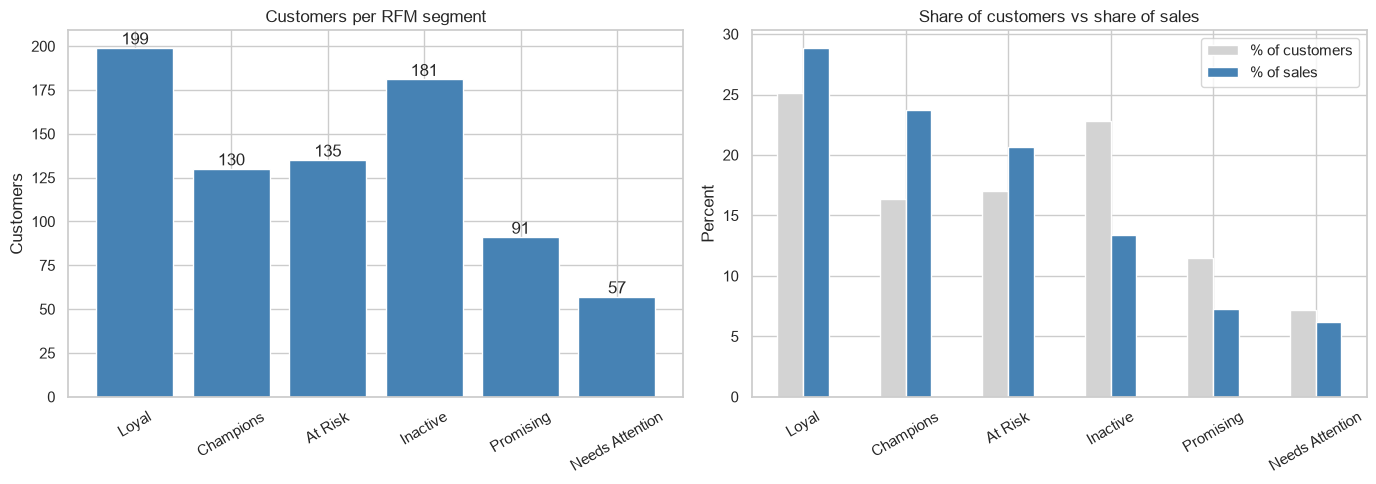

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(seg.index, seg["customers"], color="steelblue")
for i, v in enumerate(seg["customers"]):
    axes[0].text(i, v, str(v), ha="center", va="bottom")
axes[0].set_title("Customers per RFM segment")
axes[0].set_ylabel("Customers")
axes[0].tick_params(axis="x", rotation=30)

seg[["pct_customers", "pct_sales"]].plot(kind="bar", ax=axes[1],
                                           color=["lightgray", "steelblue"])
axes[1].legend(["% of customers", "% of sales"])
axes[1].set_title("Share of customers vs share of sales")
axes[1].set_xlabel("")
axes[1].set_ylabel("Percent")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("../images/customer_01_rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
type_tbl = (customers.groupby("segment")
              .agg(customers=("customer_id", "count"),
                   orders=("orders", "sum"),
                   total_sales=("total_sales", "sum"),
                   total_profit=("total_profit", "sum")))
type_tbl["sales_per_customer"] = type_tbl["total_sales"] / type_tbl["customers"]
type_tbl["orders_per_customer"] = type_tbl["orders"] / type_tbl["customers"]
type_tbl["margin_pct"] = type_tbl["total_profit"] / type_tbl["total_sales"] * 100
type_tbl

,customers,orders,total_sales,total_profit,sales_per_customer,orders_per_customer,margin_pct
segment,,,,,,,
Consumer,409,2586,"1,161,401.34","134,119.21","2,839.61",6.32,11.55
Corporate,236,1514,"706,146.37","91,979.13","2,992.15",6.42,13.03
Home Office,148,909,"429,371.78","60,310.74","2,901.16",6.14,14.05


In [8]:
cols = ["customer_name", "segment", "rfm_segment", "orders",
        "total_sales", "total_profit", "profit_margin_pct"]

print("TOP 10 customers by profit")
display(customers.nlargest(10, "total_profit")[cols])

print("BOTTOM 10 customers by profit")
display(customers.nsmallest(10, "total_profit")[cols])

TOP 10 customers by profit


,customer_name,segment,rfm_segment,orders,total_sales,total_profit,profit_margin_pct
741,Tamara Chand,Corporate,Inactive,5,"19,052.22","8,981.32",47.14
621,Raymond Buch,Consumer,Loyal,6,"15,117.34","6,976.10",46.15
669,Sanjit Chand,Consumer,At Risk,9,"14,142.33","5,757.41",40.71
327,Hunter Lopez,Consumer,Loyal,6,"12,873.30","5,622.43",43.68
6,Adrian Barton,Consumer,Champions,10,"14,473.57","5,444.81",37.62
730,Tom Ashbrook,Home Office,Needs Attention,4,"14,595.62","4,703.79",32.23
160,Christopher Martinez,Consumer,Promising,4,"8,954.02","3,899.89",43.55
424,Keith Dawkins,Corporate,At Risk,12,"8,181.26","3,038.63",37.14
48,Andy Reiter,Consumer,Loyal,6,"6,608.45","2,884.62",43.65
234,Daniel Raglin,Home Office,Champions,8,"8,350.87","2,869.08",34.36


BOTTOM 10 customers by profit


,customer_name,segment,rfm_segment,orders,total_sales,total_profit,profit_margin_pct
180,Cindy Stewart,Consumer,Loyal,6,"5,690.06","-6,626.39",-116.46
310,Grant Thornton,Corporate,Needs Attention,3,"9,351.21","-4,108.66",-43.94
459,Luke Foster,Consumer,Loyal,7,"3,930.51","-3,583.98",-91.18
711,Sharelle Roach,Home Office,Promising,5,"3,233.48","-3,333.91",-103.11
322,Henry Goldwyn,Corporate,Champions,12,"3,247.64","-2,797.96",-86.15
555,Nathan Cano,Consumer,Loyal,6,"2,218.99","-2,204.81",-99.36
666,Sean Braxton,Corporate,Loyal,7,"8,057.89","-2,082.75",-25.85
700,Sean Miller,Home Office,Needs Attention,5,"25,043.05","-1,980.74",-7.91
165,Christine Phan,Corporate,At Risk,8,"5,888.27","-1,850.30",-31.42
560,Natalie Fritzler,Consumer,Loyal,7,"8,322.83","-1,695.97",-20.38


In [9]:
customers.to_csv("../data/processed/customer_rfm.csv", index=False)
print(pd.read_csv("../data/processed/customer_rfm.csv").shape)

(793, 16)


## Customer analysis findings

**How the segments were made**
Each customer got an R, F and M score from 1 to 5. "Today" is 2017-12-31, one day after the last order. Recency and Monetary (total sales) use 5 equal groups. Frequency uses fixed groups of orders (1-3, 4-5, 6-7, 8-9, 10 or more) so customers with the same number of orders get the same score. The segment rules are my own choice, written in the code. The dataset has no churn label, so "Inactive" only means "has not bought for a long time".

**1. Champions and Loyal customers give over half of the sales.**
Finding: Champions (130) and Loyal (199) are 41.5% of customers and give 52.54% of sales. Champions have bought most recently (about 26 days ago on average) and most often (9.54 orders on average).
Insight: These two groups are the core of the business, so service quality for them matters.

**2. Loyal gives the most sales, but not the most profit.**
Finding: Loyal has 662,796 in sales, more than any other segment, but its margin is 10.57%, below the company's 12.47%. Its profit (70,027) is about the same as Champions (70,798), which has 69 fewer customers. 40 Loyal customers lose money.
Insight: Frequent buying does not guarantee profit. Profit has to be checked next to the RFM score.

**3. At Risk is the group to watch.**
Finding: At Risk has 135 customers who made 7.67 orders on average, but their last order was about 221 days ago on average. They give 20.64% of sales and the highest total profit of all segments (78,294), with the best margin (16.52%).
Insight: These are valuable customers who stopped buying recently. A reminder or a personal follow-up is worth trying. From Step 14, discounts of 30% or more tend to lose money, so a deep discount is not the first tool to use.
Careful: we do not know their normal gap between orders, so we cannot say they are leaving.

**4. Inactive customers are many but small, and more often lose money.**
Finding: Inactive has 181 customers (22.82%) but only 13.42% of sales. The average customer has 3.78 orders and the last order was about 369 days ago. 54 of 181 (about 30%) lose money, compared with about 19.5% of all customers.
Insight: Winning all of them back is not the first priority. Check which of them are profitable before spending effort.
Careful: this is a link only. We cannot say that losses made them stop buying.

**5. Promising and Needs Attention are small groups.**
Finding: Promising has 91 customers who bought recently (about 26 days ago) but have only 4.18 orders on average, with a margin of 15.30%. Needs Attention has 57 customers and the lowest margin (6.95%).
Insight: Promising customers are a chance for repeat orders. Note that "Promising" here means recent buyers with up to 5 orders, not necessarily brand-new customers.

**6. A "Champion" can still lose money.**
Finding: The top 10 customers by profit make 50,178 (17.5% of company profit) and come from all six segments. The bottom 10 lose 30,265 together (about 10.6% of company profit). Henry Goldwyn is a Champion with 12 orders but has lost 2,797.96. Cindy Stewart (Loyal) lost 6,626.39 on sales of 5,690.06. Tamara Chand, the most profitable customer (8,981.32), is in the Inactive group.
Insight: RFM shows how customers buy, not how much they earn for us. A profit column is needed beside it.

**7. The store's customer types are similar.**
Finding: Consumer, Corporate and Home Office are close: sales per customer 2,839.61 to 2,992.15, and 6.14 to 6.42 orders per customer. Home Office has the best margin (14.05%) and Consumer the lowest (11.55%). Consumer is 409 of 793 customers and 50.56% of sales.
Insight: Customer type does not separate customers much. Their buying behaviour (RFM) shows larger differences, although this is partly because RFM is built from orders and spending.

**What we cannot say**
- We see links, not causes. We do not know why customers stopped ordering or why some lost money.
- Segment names and rules are my own choice; other rules would give other groups.
- No cost price, so we cannot see why some customers are loss-making.
- This is sample data from a made-up store.